# Module 09, Part 1: Markov decision processes, returns and value functions

This notebook is the runnable companion to Part 1 of the Module 09 learning content. It checks, with code:

1. How discounting turns a stream of rewards into one number, the return, and what the discount factor does to it.
2. That the value of a policy, computed by solving the Bellman equations exactly, agrees with the average return of many simulated episodes.
3. That value iteration finds the optimal values, and that acting greedily on them gives a policy whose value is exactly those values.
4. How the optimal behaviour changes with the slip probability and the discount factor.

The environment is a 4 by 4 grid with a wall, a goal worth +1 and a pit worth -1. With probability 0.2 the agent slips at a right angle to the direction it chose. Everything is small enough to solve exactly, so nothing here is estimated unless we say so.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np

ACTIONS = ["up", "right", "down", "left"]
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]


class GridMDP:
    """Rows 0 to 3, columns 0 to 3. The goal (+1) is the top-right corner, the pit (-1) is the cell below it.
    Both are terminal. A wall cell sits at (1, 1). Every other step costs `step_cost`.
    With probability `slip` the agent moves at a right angle to the chosen direction (half each way)."""
    def __init__(self, slip=0.2, step_cost=0.0, gamma=0.9):
        self.n_rows = self.n_cols = 4
        self.goal, self.pit, self.wall = (0, 3), (1, 3), (1, 1)
        self.slip, self.step_cost, self.gamma = slip, step_cost, gamma
        self.cells = [(r, c) for r in range(4) for c in range(4) if (r, c) != self.wall]
        self.idx = {cell: i for i, cell in enumerate(self.cells)}
        self.nS, self.nA = len(self.cells), 4
        self.terminal = np.array([c in (self.goal, self.pit) for c in self.cells])
        self.P = np.zeros((self.nS, self.nA, self.nS))
        self.R = np.zeros((self.nS, self.nA))
        for cell in self.cells:
            s = self.idx[cell]
            if self.terminal[s]:
                self.P[s, :, s] = 1.0        # absorbing, no further reward
                continue
            for a in range(self.nA):
                for a2, pr in ((a, 1 - slip), ((a + 1) % 4, slip / 2), ((a - 1) % 4, slip / 2)):
                    nxt = self._move(cell, a2)
                    self.P[s, a, self.idx[nxt]] += pr
                    reward = 1.0 if nxt == self.goal else -1.0 if nxt == self.pit else step_cost
                    self.R[s, a] += pr * reward

    def _move(self, cell, a):
        r, c = cell[0] + MOVES[a][0], cell[1] + MOVES[a][1]
        if not (0 <= r < 4 and 0 <= c < 4) or (r, c) == self.wall:
            return cell
        return (r, c)

    def sample_step(self, s, a, rng):
        s2 = rng.choice(self.nS, p=self.P[s, a])
        return s2, self.R[s, a]


def evaluate_policy(mdp, pi):
    """Solve the Bellman expectation equations v = r_pi + gamma P_pi v exactly. pi has shape (nS, nA)."""
    P_pi = np.einsum("sa,sat->st", pi, mdp.P)
    r_pi = np.einsum("sa,sa->s", pi, mdp.R)
    return np.linalg.solve(np.eye(mdp.nS) - mdp.gamma * P_pi, r_pi)


def q_from_v(mdp, v):
    return mdp.R + mdp.gamma * mdp.P @ v


def value_iteration(mdp, tol=1e-10, max_iter=10000):
    v = np.zeros(mdp.nS)
    for k in range(1, max_iter + 1):
        v_new = q_from_v(mdp, v).max(1)
        done = np.abs(v_new - v).max() < tol
        v = v_new
        if done:
            break
    return v, k


def greedy_policy(q):
    pi = np.zeros_like(q)
    pi[np.arange(len(q)), q.argmax(1)] = 1.0
    return pi


def discounted_return(rewards, gamma):
    g = 0.0
    for r in reversed(rewards):
        g = r + gamma * g
    return g


def rollout_return(mdp, pi, s0, rng, max_steps=200):
    s, rewards = s0, []
    for _ in range(max_steps):
        if mdp.terminal[s]:
            break
        a = rng.choice(mdp.nA, p=pi[s])
        s, r = mdp.sample_step(s, a, rng)
        rewards.append(r)
    return discounted_return(rewards, mdp.gamma), len(rewards)


def q_learning(mdp, steps=20000, eps=0.1, alpha=0.1, seed=0, start=None, max_ep_len=100, optimistic=0.0):
    """Tabular Q-learning with an epsilon-greedy behaviour policy. Returns the Q table and how many
    episodes reached the goal. Every episode starts in `start` (default: the bottom-left corner)."""
    rng = np.random.default_rng(seed)
    start = mdp.idx[(3, 0)] if start is None else start
    Q = np.full((mdp.nS, mdp.nA), optimistic)
    Q[mdp.terminal] = 0.0
    s, ep_len, goals = start, 0, 0
    goal_state = mdp.idx[mdp.goal]
    for _ in range(steps):
        a = int(rng.integers(mdp.nA)) if rng.random() < eps else int(np.argmax(Q[s] + 1e-9 * rng.random(mdp.nA)))
        s2, r = mdp.sample_step(s, a, rng)
        Q[s, a] += alpha * (r + mdp.gamma * Q[s2].max() - Q[s, a])
        ep_len += 1
        if mdp.terminal[s2] or ep_len >= max_ep_len:
            goals += int(s2 == goal_state)
            s, ep_len = start, 0
        else:
            s = s2
    return Q, goals


def softmax_policy(theta):
    import torch
    return torch.softmax(theta, dim=1)


def exact_objective(mdp, theta, s0):
    """J(theta) = v_pi(s0) for a softmax policy with logits theta (nS by nA), computed exactly and differentiably."""
    import torch
    pi = torch.softmax(theta, dim=1)
    P = torch.as_tensor(mdp.P, dtype=torch.float64); R = torch.as_tensor(mdp.R, dtype=torch.float64)
    P_pi = torch.einsum("sa,sat->st", pi, P); r_pi = (pi * R).sum(1)
    v = torch.linalg.solve(torch.eye(mdp.nS, dtype=torch.float64) - mdp.gamma * P_pi, r_pi)
    return v[s0]


def reinforce_gradient_estimate(mdp, theta, s0, n_episodes, rng, baseline=False, max_steps=100):
    """Monte Carlo policy-gradient estimate: average over episodes of sum_t gamma^t grad log pi(a_t|s_t) (G_t - b).
    With baseline=True, b is the exact state value v_pi(s_t), which depends on the state and not on the action."""
    pi = np.exp(theta - theta.max(1, keepdims=True)); pi /= pi.sum(1, keepdims=True)
    v = evaluate_policy(mdp, pi) if baseline else np.zeros(mdp.nS)
    grads = np.zeros((n_episodes,) + theta.shape)
    for e in range(n_episodes):
        s, traj = s0, []
        for _ in range(max_steps):
            if mdp.terminal[s]:
                break
            a = rng.choice(mdp.nA, p=pi[s]); s2, r = mdp.sample_step(s, a, rng)
            traj.append((s, a, r)); s = s2
        G = 0.0
        for t in reversed(range(len(traj))):
            s_t, a_t, r_t = traj[t]
            G = r_t + mdp.gamma * G
            g = -pi[s_t].copy(); g[a_t] += 1.0          # gradient of log softmax with respect to the logits
            grads[e, s_t] += mdp.gamma ** t * g * (G - v[s_t])
    return grads

## 1. Returns and the discount factor

An episode produces rewards $r_1, r_2, \dots$. The **return** from a time step is the discounted sum $G = r_1 + \gamma r_2 + \gamma^2 r_3 + \cdots$, and the discount factor $\gamma \in [0, 1)$ decides how much the future counts.
If the reward is 1 on every step and the episode never ends, the return is the geometric series $1 / (1 - \gamma)$. We compute it for 20 steps and compare with the infinite sum, and ask how many steps carry half of the weight.

In [3]:
print(" gamma   return after 20 steps   infinite sum 1/(1-gamma)   steps until the weight halves")
for g in (0.0, 0.5, 0.9, 0.99):
    G20 = discounted_return([1.0] * 20, g)
    inf = 1 / (1 - g)
    half = int(np.ceil(np.log(0.5) / np.log(g))) if 0 < g < 1 else 1
    print(f"{g:6.2f}   {G20:20.3f}   {inf:24.3f}   {half}")

 gamma   return after 20 steps   infinite sum 1/(1-gamma)   steps until the weight halves
  0.00                  1.000                      1.000   1
  0.50                  2.000                      2.000   1
  0.90                  8.784                     10.000   7
  0.99                 18.209                    100.000   69


With $\gamma = 0.9$ a reward ten steps away is worth about a third of one received now. With $\gamma = 0.99$ the agent looks about seventy steps ahead. The discount factor is part of the problem definition: two agents with different $\gamma$ are solving different problems.

## 2. The grid, and the value of a policy

The value of a policy $v_\pi(s)$ is the expected return when starting in state $s$ and following $\pi$. It satisfies the Bellman expectation equation $v_\pi = r_\pi + \gamma P_\pi v_\pi$, a linear system, so we can solve it directly.
We evaluate the policy that picks all four directions with equal probability, and check the answer in two ways: the residual of the equation, and the average return of 20,000 simulated episodes.

In [4]:
mdp = GridMDP(slip=0.2, step_cost=0.0, gamma=0.9)
start = mdp.idx[(3, 0)]
uniform = np.full((mdp.nS, mdp.nA), 0.25)
v_random = evaluate_policy(mdp, uniform)

P_pi = np.einsum("sa,sat->st", uniform, mdp.P); r_pi = np.einsum("sa,sa->s", uniform, mdp.R)
print("largest residual of the Bellman expectation equation:", np.abs(v_random - (r_pi + mdp.gamma * P_pi @ v_random)).max())

rng = np.random.default_rng(0)
G = np.array([rollout_return(mdp, uniform, start, rng)[0] for _ in range(20000)])
print(f"value of the start cell, exact solve:           {v_random[start]:.4f}")
print(f"average return of 20,000 simulated episodes:    {G.mean():.4f}  (standard error {G.std() / np.sqrt(len(G)):.4f})")

largest residual of the Bellman expectation equation: 5.551115123125783e-17


value of the start cell, exact solve:           -0.0633
average return of 20,000 simulated episodes:    -0.0631  (standard error 0.0010)


The simulation agrees with the exact solution to within its standard error. The uniform policy is close to worthless here (about zero): it is as likely to fall into the pit as to reach the goal.

## 3. Optimal values by value iteration

The optimal values satisfy the Bellman optimality equation $v_*(s) = \max_a \left[ r(s,a) + \gamma \sum_{s'} P(s' \mid s, a)\, v_*(s') \right]$. Value iteration applies the right-hand side repeatedly until nothing changes. We check three things:
the fixed point satisfies the equation, acting greedily on it gives a policy whose own value equals $v_*$, and the number of sweeps grows as $\gamma$ approaches 1.

In [5]:
v_star, sweeps = value_iteration(mdp)
q_star = q_from_v(mdp, v_star)
pi_star = greedy_policy(q_star)
print("Bellman optimality residual:", np.abs(v_star - q_star.max(1)).max())
print("value of the greedy policy minus v*:", np.abs(evaluate_policy(mdp, pi_star) - v_star).max())
print(f"sweeps to converge: {sweeps}")
print(f"value of the start cell: optimal {v_star[start]:.4f}, uniform random {v_random[start]:.4f}")
print()
print("gamma   sweeps   value of the start cell")
for g in (0.5, 0.9, 0.99, 0.999):
    m2 = GridMDP(slip=0.2, gamma=g); v2, k2 = value_iteration(m2)
    print(f"{g:5.3f}   {k2:6d}   {v2[m2.idx[(3, 0)]]:.4f}")

Bellman optimality residual: 4.0038639070871795e-11
value of the greedy policy minus v*: 9.412010060216858e-11
sweeps to converge: 47
value of the start cell: optimal 0.4729, uniform random -0.0633

gamma   sweeps   value of the start cell
0.500       23   0.0150
0.900       47   0.4729
0.990      135   0.9228
0.999      144   0.9919


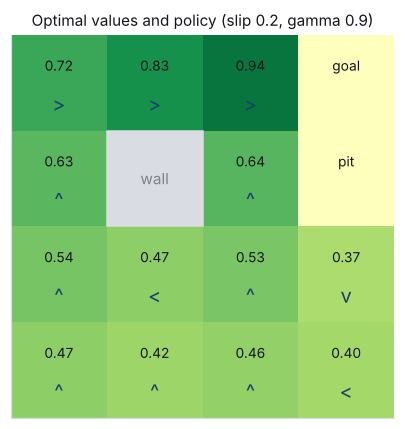

In [6]:
def draw(mdp, v, pi=None, title=""):
    fig, ax = plt.subplots(figsize=(4.6, 4.0))
    grid = np.full((4, 4), np.nan)
    for cell, s in mdp.idx.items(): grid[cell] = v[s]
    ax.imshow(grid, cmap="RdYlGn", vmin=-1, vmax=1)
    arrows = {0: "^", 1: ">", 2: "v", 3: "<"}
    for (r, c), s in mdp.idx.items():
        label = f"{v[s]:.2f}"
        if mdp.terminal[s]: label = "goal" if (r, c) == mdp.goal else "pit"
        ax.text(c, r - 0.18, label, ha="center", va="center", fontsize=9, color=INK)
        if pi is not None and not mdp.terminal[s]:
            ax.text(c, r + 0.22, arrows[int(pi[s].argmax())], ha="center", va="center", fontsize=13, color=NAVY)
    r, c = mdp.wall; ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=RULE)); ax.text(c, r, "wall", ha="center", va="center", color=MUTED)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(title, color=INK, fontsize=10)
    plt.tight_layout(); plt.show()
draw(mdp, v_star, pi_star, "Optimal values and policy (slip 0.2, gamma 0.9)")

## 4. What the optimal behaviour depends on

The best action in a cell is not fixed by the map alone. It depends on how noisy the moves are and on how far ahead the agent looks. The pit sits in the right-hand column, so the bottom-right corner (3, 3) and the cell below the pit, (2, 3), are where a risk-aware route and the shortest route can disagree.
We print the optimal action in those two cells and in the cell beside the pit, (1, 2), for several slip probabilities and discount factors, and the value of the start cell.

In [7]:
names = ["up", "right", "down", "left"]
print("slip   gamma   at (3,3)   at (2,3)   at (1,2)   start value")
for slip in (0.0, 0.2, 0.4):
    for g in (0.5, 0.9, 0.99):
        m2 = GridMDP(slip=slip, gamma=g); v2, _ = value_iteration(m2); a2 = q_from_v(m2, v2).argmax(1)
        act = lambda c: names[a2[m2.idx[c]]]
        print(f"{slip:4.1f}   {g:5.2f}   {act((3, 3)):>8}   {act((2, 3)):>8}   {act((1, 2)):>8}   {v2[m2.idx[(3, 0)]]:.4f}")

slip   gamma   at (3,3)   at (2,3)   at (1,2)   start value
 0.0    0.50         up       left         up   0.0312
 0.0    0.90         up       left         up   0.5905
 0.0    0.99         up       left         up   0.9510
 0.2    0.50       left       down         up   0.0150
 0.2    0.90       left       down         up   0.4729
 0.2    0.99       left       down       left   0.9228
 0.4    0.50       left       down       left   0.0046
 0.4    0.90       left       down       left   0.3139
 0.4    0.99       left       down       left   0.8782


Reading the table. With no slip, the agent in the bottom-right corner goes straight up the right-hand column and turns left at the cell below the pit, because it can trust its moves. Once there is any slip (0.2 or 0.4), it goes left at the corner instead and steps down, not up, in (2, 3): it keeps away from the column that holds the pit, at every discount factor we tried.
Beside the pit, in (1, 2), the best action is to go up towards the goal when slip is 0, or 0.2 with $\gamma \le 0.9$, and to move left, away from the pit, when slip is 0.4 or when the agent is far-sighted enough ($\gamma = 0.99$) for a slip into the pit to cost more than a longer route. The start cell's value falls with the slip and rises with $\gamma$: with $\gamma = 0.5$ it is worth almost nothing, because the goal is more than five steps away and each step halves the value.
The same map gives different problems.

**Try it.** Give every step a cost of 0.04 (`GridMDP(step_cost=-0.04)`) and see which of these actions change. Then try a very small discount factor and explain why the start cell's value and policy stop depending on the goal.